<div dir="rtl" style="text-align: right; font-family: Tahoma, Vazirmatn, sans-serif; line-height: 1.8;">

<h1>تکلیف: پیاده‌سازی سیستم RAG و مقایسه استراتژی‌های Prompting</h1>

<h2>مقایسه استراتژی‌های Zero-shot، Few-shot و Chain-of-Thought در سیستم RAG</h2>

<hr>

<h2>مجموعه‌داده (Dataset)</h2>

<p>
در این تکلیف از زیر مجموعه‌ای از مجموعه‌داده
<b>rajpurkar/squad</b>
و از معیارهای ارزیابی
<b>ROUGE (Recall-Oriented Understudy for Gisting Evaluation)</b>
و
شباهت معنایی
استفاده می‌کنیم.
</p>

<ul>
  <li>از مجموعه‌داده اصلی <b>SQuAD</b>، یک زیرمجموعه (<b>Subset</b>) انتخاب شده است:
    <ul>
      <li><b>100</b> پاراگراف (<b>Context</b>) از ویکی‌پدیا به عنوان corpus — فایل <b>squad_corpus_100.csv</b></li>
      <li><b>20</b> سوال و جواب (<b>Gold QA</b>) برای ارزیابی — فایل <b>squad_gold_20.csv</b></li>
      <li><b>4561</b> نمونه برای Fine-tuning — فایل <b>finetune_train.csv</b></li>
      <li><b>303</b> نمونه برای اعتبارسنجی Fine-tuning — فایل <b>finetune_val.csv</b></li>
    </ul>
  </li>
  <li>هر نمونه شامل:
    <ul>
      <li><b>context</b>: پاراگراف متنی از ویکی‌پدیا</li>
      <li><b>question</b>: سوال مرتبط با متن</li>
      <li><b>answer</b>: جواب gold به صورت span از متن</li>
    </ul>
  </li>
  <li>تمامی فایل‌های داده در فایل تمرین قرار داده شده‌اند.</li>
</ul>

<hr>

<h2>مدل‌ها (Models)</h2>

<p>
<b>Qwen/Qwen2.5-1.5B-Instruct, FacebookAI/roberta-large-mnli, BAAI/bge-small-en-v1.5</b>
</p>

<hr>

<h2>نکات مهم</h2>

<ul>
  <li>در پایان <b>هر مرحله</b>، نتایج را در یک فایل <b>CSV</b> ذخیره کنید و در فایل ارسالی پاسخ تمرین قرار دهید.</li>
  <li>فایل‌های CSV نتایج پاسخ مدل به سوالات در هر مرحله باید در فایل ارسالی پاسخ تمرین قرار داده شوند.</li>
  <li>فایل نهایی ارسالی باید یک فایل ZIP شامل همین نوت بوک و فایل پاسخ‌های مدل در هر مرحله در قال CSV باشد.</li>
  <li>مجموع نمرات این تمرین <b>57</b> نمره می‌باشد.</li>
</ul>

</div>

---
## 0  Install Requirements and import libraries and datasets

In [1]:
pip install lancedb sentence-transformers transformers accelerate rouge-score peft bitsandbytes torchao

In [3]:
pip install --upgrade torchao>=0.16.0

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn.functional as F

from transformers import AutoTokenizer, AutoModel, AutoModelForCausalLM, AutoModelForSequenceClassification
from transformers import TrainingArguments, Trainer, DataCollatorForLanguageModeling
from datasets import Dataset

import lancedb
from lancedb.pydantic import LanceModel, Vector
from lancedb.embeddings import get_registry

from rouge_score import rouge_scorer

from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, PeftModel


from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
## 1  Define Schema and Store Embeddings in LanceDB (3 Points)

<p style="text-align: left; padding:30px; background-color:rgb(12, 12, 12); border-radius: 12px; color: white; font-family: monospace;">
In this section, you need to define an appropriate Schema for storing text passages in LanceDB and use the embedding model
<b>BAAI/bge-small-en-v1.5</b>
to convert the passages from <b>squad_corpus_100.csv</b> into vector representations and store them in the database.
Then, run a sample semantic search query and display the top results to verify that the retrieval is working correctly.
</p>

In [3]:
corpus_df = pd.read_csv('/content/drive/MyDrive/DataNLP4P2/squad_corpus_100.csv')

device = "cuda" if torch.cuda.is_available() else "cpu"

embed_model = get_registry().get("sentence-transformers").create(
    name="BAAI/bge-small-en-v1.5",
    device=device
)

class ContextDocument(LanceModel):
    text: str = embed_model.SourceField()
    vector: Vector(embed_model.ndims()) = embed_model.VectorField()
    doc_id: int

db = lancedb.connect("./lancedb")

documents = []
for idx, row in corpus_df.iterrows():
    documents.append({"text": row['context'], "doc_id": idx})

table = db.create_table("squad_contexts", schema=ContextDocument, mode="overwrite")

table.add(documents)

sample_query = "At what temperature will oxygen condense?"
results = table.search(sample_query).limit(3).to_pandas()

print(f"Query: {sample_query}\n")
for idx, row in results.iterrows():
    print(f"Result {idx + 1}:")
    print(f"Text: {row['text']}")
    print(f"Distance: {row['_distance']:.4f}\n")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/133M [00:00<?, ?B/s]

... (3 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Query: At what temperature will oxygen condense?

Result 1:
Text: Oxygen condenses at 90.20 K (−182.95 °C, −297.31 °F), and freezes at 54.36 K (−218.79 °C, −361.82 °F). Both liquid and solid O
2 are clear substances with a light sky-blue color caused by absorption in the red (in contrast with the blue color of the sky, which is due to Rayleigh scattering of blue light). High-purity liquid O
2 is usually obtained by the fractional distillation of liquefied air. Liquid oxygen may also be produced by condensation out of air, using liquid nitrogen as a coolant. It is a highly reactive substance and must be segregated from combustible materials.
Distance: 0.3952

Result 2:
Text: Paleoclimatologists measure the ratio of oxygen-18 and oxygen-16 in the shells and skeletons of marine organisms to determine what the climate was like millions of years ago (see oxygen isotope ratio cycle). Seawater molecules that contain the lighter isotope, oxygen-16, evaporate at a slightly faster rate than wate

---
## 2  Define a function for semantic search in lanceDB (2 Points)

<p style="text-align: left; padding:30px; background-color:rgb(12, 12, 12); border-radius: 12px; color: white; font-family: monospace;">
In this section, you need to define a retrieval function that searches LanceDB using the questions from <b>squad_gold_20.csv</b>.
For each question, the function should return the top <b>5</b> most semantically similar passages from the database.
</p>

In [4]:
def retrieve_top_k_passages(question, k = 5):
    results = table.search(question).limit(k).to_pandas()
    passages = results['text'].tolist()
    return passages

test_question = "How many prime numbers exist?"
retrieved = retrieve_top_k_passages(test_question, k=5)

print(f"Test Retrieval for: '{test_question}'\n")
for i, passage in enumerate(retrieved, 1):
    print(f"Passage {i}: {passage[:100]}...\n")

Test Retrieval for: 'How many prime numbers exist?'

Passage 1: There are infinitely many primes, as demonstrated by Euclid around 300 BC. There is no known simple ...

Passage 2: After the Greeks, little happened with the study of prime numbers until the 17th century. In 1640 Pi...

Passage 3: A computational problem can be viewed as an infinite collection of instances together with a solutio...

Passage 4: The vast majority of Kenyans are Christian (83%), with 47.7% regarding themselves as Protestant and ...

Passage 5: For a precise definition of what it means to solve a problem using a given amount of time and space,...



---
## 3  Loading Model (2 Points)

Load the **Qwen/Qwen3.5-2B** model and its tokenizer from 🤗 Hugging Face using `AutoModelForCausalLM` and `AutoTokenizer`.

In [5]:
tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen3.5-2B")
model = AutoModelForCausalLM.from_pretrained(
    "Qwen/Qwen3.5-2B",
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    device_map="auto"
)

config.json:   0%|          | 0.00/2.91k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/6.72M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/3.35M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/12.8M [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.75k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/64.5k [00:00<?, ?B/s]

model.safetensors-00001-of-00001.safeten(…):   0%|          | 0.00/4.55G [00:00<?, ?B/s]

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

---
## 4  Search Without RAG (2 Points)

<p style="text-align: left; padding:30px; background-color:rgb(12, 12, 12); border-radius: 12px; color: white; font-family: monospace;">
In this section, define a prompt-building function and an appropriate system prompt, then answer the 20 questions from <b>squad_gold_20.csv</b> using only the model's internal knowledge, without retrieving any passages from LanceDB.
Store the predicted answers alongside the gold answers for evaluation in later sections.
You have to print the model responses.
</p>

In [6]:
def generate_answer(messages, max_new_tokens = 300, show_think = False):
    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(text, return_tensors="pt").to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            temperature=None,
            top_p=None
        )

    response = tokenizer.decode(outputs[0], skip_special_tokens=True)
    response = response.split("assistant\n")[-1].strip()

    if "</think>" in response and not show_think:
        response = response.split("</think>")[-1].strip()

    return response

In [7]:
gold_qa_df = pd.read_csv('/content/drive/MyDrive/DataNLP4P2/squad_gold_20.csv')

def build_prompt_no_rag(question, system_prompt):
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": f"Question: {question}\n\nAnswer:"}
    ]
    return messages


system_prompt_no_rag = """You are a helpful assistant. Answer the question with the SHORTEST possible answer. Give just the key fact, no explanations, no sentences, no extra words."""

no_rag_results = []

for idx, row in gold_qa_df.iterrows():
    question = row['question']
    gold_answer = row['answer']

    messages = build_prompt_no_rag(question, system_prompt_no_rag)
    predicted_answer = generate_answer(messages)

    no_rag_results.append({
        'question': question,
        'gold_answer': gold_answer,
        'predicted_answer': predicted_answer
    })

    print(f"Q{idx + 1}: {question}")
    print(f"Gold: {gold_answer}")
    print(f"Predicted: {predicted_answer}\n\n")

no_rag_df = pd.DataFrame(no_rag_results)
no_rag_df.to_csv('no_rag_results.csv', index=False)

[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.
[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.


Q1: When is the last time a fumble return touchdown happened in a Super Bowl?
Gold: Super Bowl XXVIII
Predicted: 2019




[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.


Q2: According to the AAA, what is the percentage of the gas stations that ran out of gasoline?
Gold: last week of February 1974,
Predicted: 10%




[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.


Q3: What choice did French have for surrendering land?
Gold: continental North American possessions east of the Mississippi or the Caribbean islands of Guadeloupe and Martinique
Predicted: The French had the choice to surrender land to the British in the Treaty of Paris (1783).




... (28 outputs left out)

[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.


Q18: Who developed the actinide concept?
Gold: Yuan T. Lee
Predicted: Henry Moseley




[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.


Q19: At what temperature will oxygen condense?
Gold: 90.20 K
Predicted: -183°C


Q20: What is another term for rotors?
Gold: rotating discs
Predicted: Blades




---
## 5 RAG - ZeroShot (2 Points)

<p style="text-align: left; padding:30px; background-color:rgb(12, 12, 12); border-radius: 12px; color: white; font-family: monospace;">
In this section, implement a <b>Zero-shot</b> RAG pipeline. For each question in <b>squad_gold_20.csv</b>,
retrieve the top 5 relevant passages from LanceDB and construct a prompt that includes the retrieved context.
The model should answer the question based only on the provided passages, without any examples or reasoning steps.
Store the predicted answers for evaluation in later sections.
You have to print the model responses.
</p>

In [18]:
def build_prompt_zero_shot(question, contexts):
    context_text = "\n\n".join([f"[{i+1}] {ctx}" for i, ctx in enumerate(contexts)])

    system_prompt = """You are a helpful assistant. Answer the question based ONLY on the provided context passages.

IMPORTANT RULES:
- Your answer MUST be VERY SHORT (1-5 words maximum)
- Give ONLY the key fact, name, number, or date
- No full sentences
- No explanations
- No introductory phrases like "The answer is" or "According to"
- Just the direct answer"""

    user_message = f"""Context:
{context_text}

Question: {question}

Answer:"""

    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_message}
    ]
    return messages

zero_shot_results = []

for idx, row in gold_qa_df.iterrows():
    question = row['question']
    gold_answer = row['answer']

    contexts = retrieve_top_k_passages(question, k=5)

    messages = build_prompt_zero_shot(question, contexts)
    predicted_answer = generate_answer(messages)

    zero_shot_results.append({
        'question': question,
        'gold_answer': gold_answer,
        'predicted_answer': predicted_answer,
        'retrieved_contexts': contexts
    })

    print(f"Q{idx + 1}: {question}")
    print(f"Gold: {gold_answer}")
    print(f"Predicted: {predicted_answer}\n\n")

zero_shot_df = pd.DataFrame(zero_shot_results)
zero_shot_df.to_csv('zero_shot_rag_results.csv', index=False)

[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.
[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.


Q1: When is the last time a fumble return touchdown happened in a Super Bowl?
Gold: Super Bowl XXVIII
Predicted: 1993 season




[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.


Q2: According to the AAA, what is the percentage of the gas stations that ran out of gasoline?
Gold: last week of February 1974,
Predicted: 20 percent




[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.


Q3: What choice did French have for surrendering land?
Gold: continental North American possessions east of the Mississippi or the Caribbean islands of Guadeloupe and Martinique
Predicted: Cede North American possessions or retain Caribbean islands.




... (28 outputs left out)

[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.


Q18: Who developed the actinide concept?
Gold: Yuan T. Lee
Predicted: Yuan T. Lee




[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.


Q19: At what temperature will oxygen condense?
Gold: 90.20 K
Predicted: 90.20 K


Q20: What is another term for rotors?
Gold: rotating discs
Predicted: Rotating discs




---
## 6 RAG - FewShot (2 Points)

<p style="text-align: left; padding:30px; background-color:rgb(12, 12, 12); border-radius: 12px; color: white; font-family: monospace;">
In this section, implement a <b>Few-shot</b> RAG pipeline. For each question in <b>squad_gold_20.csv</b>,
retrieve the top 5 relevant passages from LanceDB and construct a prompt that includes the retrieved context along with <b>3 examples</b> of question-answer pairs.
The examples should guide the model on the expected format and style of the answer.
Store the predicted answers for evaluation in later sections.
You have to print the model responses.
</p>

In [ ]:
def build_prompt_few_shot(question, contexts):
    context_text = "\n\n".join([f"[{i+1}] {ctx}" for i, ctx in enumerate(contexts)])

    system_prompt = """You are a helpful assistant. Answer questions based on the provided context passages. Follow the format shown in the examples."""

    user_message = f"""Context:
{context_text}

Here are some examples:

Example 1:
Question: What is the capital of France?
Answer: Paris

Example 2:
Question: Who wrote Romeo and Juliet?
Answer: William Shakespeare

Example 3:
Question: What year did World War II end?
Answer: 1945

Now answer this question:
Question: {question}

Answer:"""

    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_message}
    ]
    return messages

def clean_few_shot_answer(predicted_answer):
    patterns = [
        "Answer:",
        "answer:",
        "ANSWER:",
    ]

    for pattern in patterns:
        if predicted_answer.startswith(pattern):
            return predicted_answer[len(pattern):].strip()

    if "Answer:" in predicted_answer:
        parts = predicted_answer.split("Answer:")
        return parts[-1].strip()

    return predicted_answer


few_shot_results = []

for idx, row in gold_qa_df.iterrows():
    question = row['question']
    gold_answer = row['answer']

    contexts = retrieve_top_k_passages(question, k=5)

    messages = build_prompt_few_shot(question, contexts)
    predicted_answer = generate_answer(messages)
    predicted_answer = clean_few_shot_answer(predicted_answer)

    few_shot_results.append({
        'question': question,
        'gold_answer': gold_answer,
        'predicted_answer': predicted_answer,
        'retrieved_contexts': contexts
    })

    print(f"Q{idx + 1}: {question}")
    print(f"Gold: {gold_answer}")
    print(f"Predicted: {predicted_answer}\n\n")

few_shot_df = pd.DataFrame(few_shot_results)
few_shot_df.to_csv('few_shot_rag_results.csv', index=False)

[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.
[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.


Q1: When is the last time a fumble return touchdown happened in a Super Bowl?
Gold: Super Bowl XXVIII
Predicted: 1993




[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.


Q2: According to the AAA, what is the percentage of the gas stations that ran out of gasoline?
Gold: last week of February 1974,
Predicted: 20%




[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.


Q3: What choice did French have for surrendering land?
Gold: continental North American possessions east of the Mississippi or the Caribbean islands of Guadeloupe and Martinique
Predicted: France chose to cede its continental North American possessions east of the Mississippi or the Caribbean islands of Guadeloupe and Martinique.




... (28 outputs left out)

[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.


Q18: Who developed the actinide concept?
Gold: Yuan T. Lee
Predicted: Yuan T. Lee




[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.


Q19: At what temperature will oxygen condense?
Gold: 90.20 K
Predicted: 90.20 K (−182.95 °C, −297.31 °F)


Q20: What is another term for rotors?
Gold: rotating discs
Predicted: Stators




---
## 7 RAG - CoT (2 Points)

<p style="text-align: left; padding:30px; background-color:rgb(12, 12, 12); border-radius: 12px; color: white; font-family: monospace;">
In this section, implement a <b>Chain-of-Thought (CoT)</b> RAG pipeline. For each question in <b>squad_gold_20.csv</b>,
retrieve the top 5 relevant passages from LanceDB and construct a prompt that guides the model to reason step by step before giving the final answer.
Store both the full reasoning output and the final extracted answer for evaluation in later sections.
You have to print the model responses.
</p>

In [ ]:
def build_prompt_cot(question, contexts):
    context_text = "\n\n".join([f"[{i+1}] {ctx}" for i, ctx in enumerate(contexts)])

    system_prompt = """You are a helpful assistant. Think step by step to answer questions based ONLY on the provided context.

Format your response EXACTLY like this:
1. [Your reasoning step 1]
2. [Your reasoning step 2]
3. [Your reasoning step 3]
FINAL ANSWER: [Just the answer, 1-5 words maximum]

IMPORTANT RULES:
- The FINAL ANSWER must be ONLY the answer (1-5 words)
- Do NOT include explanations, sentences, or extra text in FINAL ANSWER
- Do NOT include "The answer is" or "Answer:" in FINAL ANSWER
- If the answer is a single word, number, or name, just give that"""

    user_message = f"""Context:
{context_text}

Question: {question}

Now think step by step and end with FINAL ANSWER:"""

    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_message}
    ]
    return messages

def extract_final_answer(cot_response):
    markers = [
        "FINAL ANSWER:",
        "final answer:",
        "Final Answer:",
        "Answer:",
        "therefore,",
        "so,",
        "thus,"
    ]

    for marker in markers:
        if marker in cot_response:
            parts = cot_response.split(marker)
            if len(parts) > 1:
                answer = parts[-1].strip()
                answer = answer.split('\n')[0].strip()
                if answer.endswith('.'):
                    answer = answer[:-1].strip()
                return answer

    sentences = cot_response.split('.')
    for sentence in reversed(sentences):
        sentence = sentence.strip()
        if sentence and len(sentence.split()) > 1:
            return sentence

    return cot_response.strip()

cot_results = []

for idx, row in gold_qa_df.iterrows():
    question = row['question']
    gold_answer = row['answer']

    contexts = retrieve_top_k_passages(question, k=5)

    messages = build_prompt_cot(question, contexts)
    full_response = generate_answer(messages, max_new_tokens=200)

    final_answer = extract_final_answer(full_response)

    cot_results.append({
        'question': question,
        'gold_answer': gold_answer,
        'full_reasoning': full_response,
        'final_answer': final_answer,
        'retrieved_contexts': contexts
    })

    print(f"Q{idx + 1}: {question}")
    print(f"Gold: {gold_answer}")
    print(f"Reasoning: {full_response}")
    print(f"Final Answer: {final_answer}\n\n")

cot_df = pd.DataFrame(cot_results)
cot_df.to_csv('cot_rag_results.csv', index=False)

[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.
[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.


Q1: When is the last time a fumble return touchdown happened in a Super Bowl?
Gold: Super Bowl XXVIII
Reasoning: 1. The text states that the Broncos touchdown was the first fumble return in a Super Bowl since Super Bowl XXVIII.
2. Super Bowl XXVIII took place at the end of the 1993 season.
3. Therefore, the last time this occurred was in 1993.

FINAL ANSWER: 1993
Final Answer: 1993




[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.


Q2: According to the AAA, what is the percentage of the gas stations that ran out of gasoline?
Gold: last week of February 1974,
Reasoning: 1. The text mentions the American Automobile Association (AAA) in the context of gasoline station fuel availability.
2. The specific statistic provided is that in the last week of February 1974, 20% of American gasoline stations had no fuel.
3. The question asks for the percentage of gas stations that ran out of gasoline according to the AAA.
4. The number associated with the AAA statistic is 20%.

FINAL ANSWER: 20%
Final Answer: 20%




[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.


Q3: What choice did French have for surrendering land?
Gold: continental North American possessions east of the Mississippi or the Caribbean islands of Guadeloupe and Martinique
Reasoning: 1. The text states that the British offered France a choice regarding their North American possessions.
2. The specific options mentioned were either ceding continental North American possessions east of the Mississippi or retaining Caribbean islands.
3. The text explicitly notes that France chose to cede the former (continental possessions).
4. Therefore, the choice was between ceding continental North American possessions or retaining Caribbean islands.

FINAL ANSWER: ceding continental North American possessions or retaining Caribbean islands
Final Answer: ceding continental North American possessions or retaining Caribbean islands




... (28 outputs left out)

[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.


Q18: Who developed the actinide concept?
Gold: Yuan T. Lee
Reasoning: 1. Scan the text for keywords related to "actinide concept".
2. Locate the sentence mentioning "actinide concept" in the first paragraph.
3. Identify the name associated with that concept in that sentence.
4. Extract the name "Yuan T. Lee".

FINAL ANSWER: Yuan T. Lee
Final Answer: Yuan T. Lee




[transformers] Setting `pad_token_id` to `eos_token_id`:248044 for open-end generation.


Q19: At what temperature will oxygen condense?
Gold: 90.20 K
Reasoning: 1. The text states that oxygen condenses at 90.20 K.
2. It also provides the equivalent temperature in Celsius as -182.95 °C.
3. The question asks for the temperature at which oxygen condenses.
4. Both values are valid representations of the same fact found in the context.
5. The most direct answer is the Kelvin value mentioned first.

FINAL ANSWER: 90.20 K
Final Answer: 90.20 K


Q20: What is another term for rotors?
Gold: rotating discs
Reasoning: 1. The text defines a steam turbine as consisting of rotors and stators.
2. It describes the rotors as having a "propeller-like arrangement of blades".
3. It also mentions that a turbine rotor is a "rotating disc".
4. The question asks for another term for rotors.
5. Based on the description of the physical object, "rotating disc" is the alternative term provided in the text.

FINAL ANSWER: Rotating disc
Final Answer: Rotating disc




---
## 8 Evaluation with ROUGE (2 Points)

<p style="text-align: left; padding:30px; background-color:rgb(12, 12, 12); border-radius: 12px; color: white; font-family: monospace;">
In this section, evaluate the predicted answers from all four methods (No RAG, Zero-shot, Few-shot, and CoT)
using <b>ROUGE-1</b>, <b>ROUGE-2</b>, and <b>ROUGE-L</b> metrics with the <b>rouge-score</b> library.
For each method, compute and display the <b>average score</b> across all 20 questions.
Display the final results in a comparison table to analyze the impact of each prompting strategy.
</p>

In [19]:
def calculate_rouge_scores(predictions, references):
    scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)

    rouge1_scores = []
    rouge2_scores = []
    rougeL_scores = []

    for pred, ref in zip(predictions, references):
        scores = scorer.score(ref, pred)
        rouge1_scores.append(scores['rouge1'].fmeasure)
        rouge2_scores.append(scores['rouge2'].fmeasure)
        rougeL_scores.append(scores['rougeL'].fmeasure)

    return {
        'ROUGE-1': np.mean(rouge1_scores),
        'ROUGE-2': np.mean(rouge2_scores),
        'ROUGE-L': np.mean(rougeL_scores)
    }

gold_answers = gold_qa_df['answer'].tolist()

no_rag_predictions = no_rag_df['predicted_answer'].tolist()
zero_shot_predictions = zero_shot_df['predicted_answer'].tolist()
few_shot_predictions = few_shot_df['predicted_answer'].tolist()
cot_predictions = cot_df['final_answer'].tolist()

results_summary = {}

methods = {
    'No RAG': no_rag_predictions,
    'Zero-shot RAG': zero_shot_predictions,
    'Few-shot RAG': few_shot_predictions,
    'CoT RAG': cot_predictions
}

for method_name, predictions in methods.items():
    scores = calculate_rouge_scores(predictions, gold_answers)
    results_summary[method_name] = scores

    print(f"{method_name}:")
    print(f"  ROUGE-1: {scores['ROUGE-1']:.4f}")
    print(f"  ROUGE-2: {scores['ROUGE-2']:.4f}")
    print(f"  ROUGE-L: {scores['ROUGE-L']:.4f}")
    print()


No RAG:
  ROUGE-1: 0.1279
  ROUGE-2: 0.0143
  ROUGE-L: 0.1252

Zero-shot RAG:
  ROUGE-1: 0.6513
  ROUGE-2: 0.4768
  ROUGE-L: 0.6513

Few-shot RAG:
  ROUGE-1: 0.5233
  ROUGE-2: 0.4278
  ROUGE-L: 0.5233

CoT RAG:
  ROUGE-1: 0.6369
  ROUGE-2: 0.4074
  ROUGE-L: 0.6369



In [20]:
comparison_df = pd.DataFrame(results_summary).T
comparison_df = comparison_df.round(4)
comparison_df['Average'] = comparison_df.mean(axis=1)
comparison_df = comparison_df.sort_values('Average', ascending=False)
comparison_df.to_csv('rouge_comparison.csv')
comparison_df

,ROUGE-1,ROUGE-2,ROUGE-L,Average
Zero-shot RAG,0.6513,0.4768,0.6513,0.593133
CoT RAG,0.6369,0.4074,0.6369,0.560400
Few-shot RAG,0.5233,0.4278,0.5233,0.491467
No RAG,0.1279,0.0143,0.1252,0.089133


---
## 8.1  Analyze ROUGE Scores (2 Points)

> **💬 Question (written answer — ~200 words):**  
> Analyze the ROUGE scores obtained from all four methods (No RAG, Zero-shot, Few-shot, and CoT).  
> - Which method achieved the highest ROUGE scores and why?  
> - How much did RAG improve the results compared to No RAG baseline?  
> - What does the difference between ROUGE-1 and ROUGE-L tell you about the quality of the generated answers?  
> - Based on your results, which prompting strategy would you recommend and why?  

<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
روش Zero-shot بهترین عمکلرد کلی را به دست آورد. در همه system prompt ها از مدل خواسته شد تا جواب ها کوتاه و دقیق باشند. اما احتمالا عملکرد بهتر این روش به این خاطر است که پرامپت داده شده درخواستی برای هیچ مرحله ای که باعث حواس پرتی مدل شود را ندارد (مثل مثال های Few-Shot و استدلال در CoT) و صرفا جواب دقیق و کوتاه را می‌خواهد.
</div>
<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
 به طور کلی RAG باعث بهبود عملکرد مدل نسبت به حالت پایه شد و بسته به نوع RAG و امتیاز Rouge، باعث افزایش 30 تا 53 درصدی این امتیاز شد. مثلا ROUGE-1 از 0.12 در حالت پایه، به 0.65 در Zero-shot رسید.
</div>

<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
مقادیر Rouge-1 و Rouge-L در روش های مبتنی بر RAG برابر هستند.
این برابری نشان می‌دهد که  پاسخ‌های پیش بینی شده بسیار کوتاه و فشرده بوده و معمولا از یک کلمه، عدد یا عبارتی کوتاه تشکیل شده‌اند که با پاسخ مرجع مطابقت دارد. این یعنی مدل به درستی قوانین فرمت دهی را رعایت کرده و به جای تولید جملات طولانی، مستقیم به سراغ اصل پاسخ رفته است.
</div>

<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
با توجه به معیار ها، Zero-shot RAG بهترین گزینه است. زیرا بالاترین همپوشانی واژه ای یا همان Rouge-1 را دارد و همچنین مصرف توکن آن نسبت به روش هاش Few-Shot و CoT کمتر است.
</div>

---
## 9 Evaluation with RoBERTa

<p style="text-align: left; padding:30px; background-color:rgb(12, 12, 12); border-radius: 12px; color: white; font-family: monospace;">
In this section, evaluate the predicted answers from all four methods (No RAG, Zero-shot, Few-shot, and CoT)
using a <b>RoBERTa-based NLI model</b> loaded from Hugging Face (<b>FacebookAI/roberta-large-mnli</b>) to measure semantic equivalence between the predicted and gold answers.
For each predicted answer, the model classifies the relationship with the gold answer as <b>entailment</b>, <b>neutral</b>, or <b>contradiction</b>.
For each method, compute and display the <b>average percentage</b> of each label across all 20 questions.
Display the final results in a comparison table alongside the ROUGE scores to analyze the impact of each prompting strategy.
</p>

## 9.1 Load RoBERTa NLI (2 Points)

Load the RoBERTa NLI model and tokenizer from Hugging Face (`FacebookAI/roberta-large-mnli`).

In [21]:
nli_model_name = "FacebookAI/roberta-large-mnli"

nli_tokenizer = AutoTokenizer.from_pretrained(nli_model_name)
nli_model = AutoModelForSequenceClassification.from_pretrained(
    nli_model_name,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto" if torch.cuda.is_available() else None
)

config.json:   0%|          | 0.00/688 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.43G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-large-mnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


## 9.2  Define NLI Scoring Function (2 Points)

Define a function that takes a list of predicted answers and gold answers, and for each pair classifies the relationship as **entailment**, **neutral**, or **contradiction**.

In [ ]:
def classify_nli_batch(predictions, references):

    results = []

    for pred, ref in zip(predictions, references):
        inputs = nli_tokenizer(
            ref,
            pred,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=512
        ).to(nli_model.device)

        with torch.no_grad():
            outputs = nli_model(**inputs)
            logits = outputs.logits
            probs = F.softmax(logits, dim=1)[0]

        label_map = {0: 'contradiction', 1: 'neutral', 2: 'entailment'}
        predicted_label = torch.argmax(probs).item()

        results.append({
            'label': label_map[predicted_label],
            'contradiction': probs[0].item(),
            'neutral': probs[1].item(),
            'entailment': probs[2].item()
        })

    return results

def calculate_nli_statistics(nli_results):
    total = len(nli_results)

    entailment_count = sum(1 for r in nli_results if r['label'] == 'entailment')
    neutral_count = sum(1 for r in nli_results if r['label'] == 'neutral')
    contradiction_count = sum(1 for r in nli_results if r['label'] == 'contradiction')

    return {
        'Entailment %': (entailment_count / total) * 100,
        'Neutral %': (neutral_count / total) * 100,
        'Contradiction %': (contradiction_count / total) * 100
    }


test_pred = ["ّFootbal"]
test_ref = ["Soccer"]
test_result = classify_nli_batch(test_pred, test_ref)
print(f"Prediction: {test_pred[0]}")
print(f"Reference: {test_ref[0]}")
print(f"Label: {test_result[0]['label']}")
print(f"Probabilities: {test_result[0]}")

Prediction: Footbal
Reference: Soccer
Label: entailment
Probabilities: {'label': 'entailment', 'contradiction': 0.182373046875, 'neutral': 0.2154541015625, 'entailment': 0.60205078125}


## 9.3  Run Evaluation and Display Results (1 Points)

Run the NLI scoring function on all four methods and display the average percentage of each label in a comparison table.
Also merge the NLI results with the ROUGE scores from the previous section into a single final table.

In [ ]:
nli_results_summary = {}

for method_name, predictions in methods.items():
    print(f"Evaluating {method_name}...")
    nli_results = classify_nli_batch(predictions, gold_answers)
    stats = calculate_nli_statistics(nli_results)
    nli_results_summary[method_name] = stats

    print(f"  Entailment: {stats['Entailment %']:.2f}%")
    print(f"  Neutral: {stats['Neutral %']:.2f}%")
    print(f"  Contradiction: {stats['Contradiction %']:.2f}%\n")

nli_comparison_df = pd.DataFrame(nli_results_summary).T
nli_comparison_df = nli_comparison_df.round(2)

print(nli_comparison_df.to_string())

final_comparison = comparison_df.copy()
final_comparison = final_comparison.drop('Average', axis=1)

for col in nli_comparison_df.columns:
    final_comparison[col] = nli_comparison_df[col]

final_comparison.to_csv('final_comparison_rouge_nli.csv')
final_comparison

Evaluating No RAG...
  Entailment: 10.00%
  Neutral: 40.00%
  Contradiction: 50.00%

Evaluating Zero-shot RAG...
  Entailment: 60.00%
  Neutral: 40.00%
  Contradiction: 0.00%

Evaluating Few-shot RAG...
  Entailment: 45.00%
  Neutral: 40.00%
  Contradiction: 15.00%

Evaluating CoT RAG...
  Entailment: 65.00%
  Neutral: 25.00%
  Contradiction: 10.00%

               Entailment %  Neutral %  Contradiction %
No RAG                 10.0       40.0             50.0
Zero-shot RAG          60.0       40.0              0.0
Few-shot RAG           45.0       40.0             15.0
CoT RAG                65.0       25.0             10.0


,ROUGE-1,ROUGE-2,ROUGE-L,Entailment %,Neutral %,Contradiction %
Zero-shot RAG,0.6513,0.4768,0.6513,60.0,40.0,0.0
CoT RAG,0.6369,0.4074,0.6369,65.0,25.0,10.0
Few-shot RAG,0.5233,0.4278,0.5233,45.0,40.0,15.0
No RAG,0.1279,0.0143,0.1252,10.0,40.0,50.0


---
## 9.4  Analyze RoBERTa NLI Results (4 Points)

> **💬 Question (written answer — ~200 words):**  
> Analyze the RoBERTa NLI results obtained from all four methods (No RAG, Zero-shot, Few-shot, and CoT).  
> - Which method achieved the highest entailment percentage and why?  
> - How does the contradiction rate change between No RAG and RAG-based methods?  
> - Comparing the NLI results with the ROUGE scores, do both metrics agree on which method performs best?  
> - What does a high neutral percentage tell you about the quality of the generated answers?  


<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
روش CoT RAG بیشترین entailment را دارد که 65 درصد است و به این خاطر است که پرامپت نویسی CoT باعث شده پاسخ های مدل از نظر معنایی سازگاری بیشتری با پاسخ مرجع داشته باشند حتی اگر واژگان آن ها دقیقا یکسان نباشند.
</div>

<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
نرخ contradiction  با اضافه شدن RAG بسیار کمتر شده است و از 50% به 15%، 10% و حتی 0% رسیده است. این موضوع نشان دهنده hallucination در مدل های بدون بازیابی و تاثیر بازیابی در کاهش آن است.
</div>

<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
نتایج هر دو نشان دهند برتری RAG نسبت به حالت پایه است. اما Rouge روش Zero-shot و NLI روش CoT را بهتر می‌دانند. این اختلاف به این خاطر است که ROUGE بیشتر به تطابق سطحی کلمات حساس است، در حالی که NLI بررسی می‌کند آیا معنای پاسخ با مرجع سازگار است یا نه. پس Zero-shot شباهت کلمه ای بیشتر و CoT شباهت معنایی بیشتری دارد.
</div>

<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
درصد بالای neutral یعنی خیلی از پاسخ های تولید شده نه کاملا درست و نه کاملا غلط هستند و این درصد تقریبا در همه حالت ها حدود 40% است به جز CoT. به طور کلی این مقدار یعنی مدل در بسیاری از موارد پاسخ هایی تولید کرده که تا حدی درست، اما ناقص یا متفاوت نسبت به مرجع بوده اند. بنابراین، هنوز جای بهبود در دقت و کامل بودن پاسخ ها وجود دارد.
</div>

---
## 10  Fine-Tuning With LoRA



<p style="text-align: left; padding:30px; background-color:rgb(12, 12, 12); border-radius: 12px; color: white; font-family: monospace;">
In this section, you need to fine-tune the <b>Qwen/Qwen 3.5 2B</b> model using <b>LoRA (Low-Rank Adaptation)</b>.
To avoid <b>Out of Memory</b> errors, please <b>restart your runtime</b> before running this section and reinstall the required libraries from the <b>requirements.txt</b> file.
</p>

## 10.1 Load Fine-Tuning Dataset

Load the fine-tuning datasets from **finetune_train.csv** and **finetune_val.csv** and prepare them for tokenization.

In [5]:
train_df = pd.read_csv('/content/drive/MyDrive/DataNLP4P2/finetune_train.csv')
val_df = pd.read_csv('/content/drive/MyDrive/DataNLP4P2/finetune_val.csv')

train_dataset = Dataset.from_pandas(train_df)
val_dataset = Dataset.from_pandas(val_df)

## 10.2 Load Model and Tokenizer (2 Points)

Load the **Qwen/Qwen3.5-2B** model and its tokenizer from 🤗 Hugging Face using `AutoModelForCausalLM` and `AutoTokenizer`.

In [6]:
device = "cuda" if torch.cuda.is_available() else "cpu"

finetune_tokenizer  = AutoTokenizer.from_pretrained("Qwen/Qwen3.5-2B")
finetune_model  = AutoModelForCausalLM.from_pretrained(
    "Qwen/Qwen3.5-2B",
    torch_dtype=torch.float16,
    device_map="auto"
)

finetune_model.gradient_checkpointing_enable()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

## 10.3 Tokenize Dataset (4 Points)

Define a tokenization function using the loaded tokenizer and apply it to both the train and validation datasets.

Min length: 26
Max length: 700
Mean length: 130.69120065789474
Median length: 117.0
90th percentile: 227.0
95th percentile: 270.0
99th percentile: 358.3699999999999


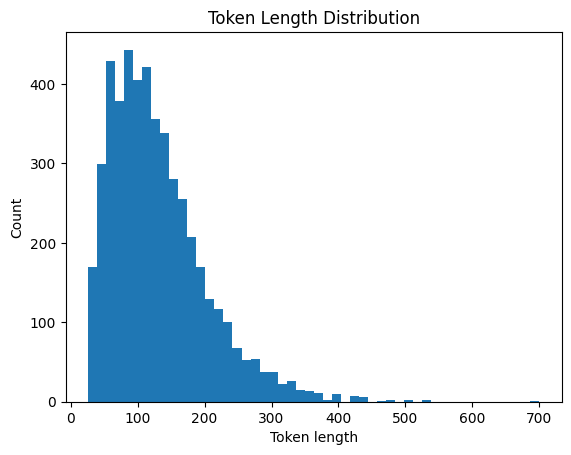

In [ ]:
def get_token_lengths(dataset, tokenizer, text_column="text"):
    lengths = []
    for text in dataset[text_column]:
        tokens = tokenizer(text, truncation=False, add_special_tokens=True)
        lengths.append(len(tokens["input_ids"]))
    return lengths

train_lengths = get_token_lengths(train_df, finetune_tokenizer, text_column="text")
val_lengths = get_token_lengths(val_df, finetune_tokenizer, text_column="text")

all_lengths = train_lengths + val_lengths

print("Min length:", np.min(all_lengths))
print("Max length:", np.max(all_lengths))
print("Mean length:", np.mean(all_lengths))
print("Median length:", np.median(all_lengths))
print("90th percentile:", np.percentile(all_lengths, 90))
print("95th percentile:", np.percentile(all_lengths, 95))
print("99th percentile:", np.percentile(all_lengths, 99))

plt.hist(all_lengths, bins=50)
plt.xlabel("Token length")
plt.ylabel("Count")
plt.title("Token Length Distribution")
plt.show()


In [ ]:
def tokenize_function(examples):
    tokenized = finetune_tokenizer(
        examples['text'],
        truncation=True,
        padding="max_length",
        max_length=360,
        return_tensors=None
    )

    tokenized["labels"] = tokenized["input_ids"].copy()

    return tokenized

train_tokenized = train_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=train_dataset.column_names,
    desc="Tokenizing train"
)

val_tokenized = val_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=val_dataset.column_names,
    desc="Tokenizing val"
)

Tokenizing train:   0%|          | 0/4561 [00:00<?, ? examples/s]

Tokenizing val:   0%|          | 0/303 [00:00<?, ? examples/s]

## 10.4 Fine-Tune with LoRA (8 Points)

Fine-tune the model using **LoRA** with the following configuration:
- `r=8`, `lora_alpha=16`, `lora_dropout=0.05`
- `target_modules`: `q_proj` and `v_proj`
- `num_train_epochs=1`
- `per_device_train_batch_size=2`
- `gradient_accumulation_steps=8`
- `learning_rate=2e-4`
- Enable `fp16` and `gradient_checkpointing` to avoid out of memory errors.

After training, save the fine-tuned model to **./lora_output** or GOOGLE DRIVE for use in the next sections.

In [ ]:
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=["q_proj", "v_proj"],
    task_type="CAUSAL_LM",
    bias="none",
)

finetune_model = get_peft_model(finetune_model, lora_config)
finetune_model.print_trainable_parameters()

training_args = TrainingArguments(
    output_dir="./lora_output",
    num_train_epochs=1,
    per_device_train_batch_size=2,
    gradient_accumulation_steps=8,
    learning_rate=2e-4,
    fp16=torch.cuda.is_available(),
    gradient_checkpointing=True,
    logging_steps=50,
    save_strategy="epoch",
    report_to="none",
    eval_strategy="epoch",
    eval_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss"
)

data_collator = DataCollatorForLanguageModeling(
    tokenizer=finetune_tokenizer,
    mlm=False,
)

trainer = Trainer(
    model=finetune_model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    data_collator=data_collator,
)

print("Starting fine-tuning")
trainer.train()

finetune_model.save_pretrained("./lora_output")
finetune_tokenizer.save_pretrained("./lora_output")



trainable params: 417,792 || all params: 1,882,242,880 || trainable%: 0.0222
Starting fine-tuning


Epoch,Training Loss,Validation Loss
1,2.502860,2.570231


('./lora_output/tokenizer_config.json',
 './lora_output/chat_template.jinja',
 './lora_output/tokenizer.json')

In [15]:
!cp -r ./lora_output /content/drive/MyDrive/DataNLP4P2/

## 10.5 Generate Answers with Fine-Tuned Model (2 Points)

Using the fine-tuned model, generate answers for the 20 questions in **squad_gold_20.csv** without providing any context (No RAG).
Store the predicted answers alongside the gold answers in a CSV file.

In [ ]:
base_model = AutoModelForCausalLM.from_pretrained(
    "Qwen/Qwen3.5-2B",
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto"
)

finetuned_model = PeftModel.from_pretrained(base_model, "./lora_output")
finetuned_model.eval()

print("Fine-tuned model loaded successfully!")

def generate_answer_finetuned(question: str, max_new_tokens: int = 50) -> str:
    messages = [
        {"role": "system", "content": "You are a helpful assistant. Answer the question with the SHORTEST possible answer. Give just the key fact, no explanations, no sentences, no extra words."},
        {"role": "user", "content": f"Question: {question}\n\nAnswer:"}
    ]

    text = finetune_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = finetune_tokenizer(
        text,
        return_tensors="pt"
    ).to(finetuned_model.device)

    with torch.no_grad():
        outputs = finetuned_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            temperature=None,
            top_p=None,
            pad_token_id=finetune_tokenizer.pad_token_id,
            eos_token_id=finetune_tokenizer.eos_token_id,
        )

    response = finetune_tokenizer.decode(outputs[0], skip_special_tokens=True)
    response = response.split("assistant\n")[-1].strip()

    if "</think>" in response:
        response = response.split("</think>")[-1].strip()

    return response

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Fine-tuned model loaded successfully!


In [ ]:
finetuned_results = []

for idx, row in gold_qa_df.iterrows():
    question = row['question']
    gold_answer = row['answer']

    predicted_answer = generate_answer_finetuned(question)

    finetuned_results.append({
        'question': question,
        'gold_answer': gold_answer,
        'predicted_answer': predicted_answer
    })

    print(f"Q{idx + 1}: {question}")
    print(f"Gold: {gold_answer}")
    print(f"Predicted: {predicted_answer}\n\n")

finetuned_df = pd.DataFrame(finetuned_results)
finetuned_df.to_csv('finetuned_model_results.csv', index=False)

Q1: When is the last time a fumble return touchdown happened in a Super Bowl?
Gold: Super Bowl XXVIII
Predicted: 2019


Q2: According to the AAA, what is the percentage of the gas stations that ran out of gasoline?
Gold: last week of February 1974,
Predicted: 10%


Q3: What choice did French have for surrendering land?
Gold: continental North American possessions east of the Mississippi or the Caribbean islands of Guadeloupe and Martinique
Predicted: The French had the choice to surrender land to the British in the Treaty of Paris (1783).


Q4: Which articles state that the member states' rights to deliver public services may not be obstructed?
Gold: Articles 106 and 107
Predicted: Articles 10 and 11 of the Treaty on European Union


Q5: The time required to output an answer on a deterministic Turing machine is expressed as what?
Gold: state transitions
Predicted: The time required is the number of steps in the computation.


Q6: How many general questions are available to opposition l

## 10.6 Evaluate with ROUGE (2 Points)

Compute **ROUGE-1**, **ROUGE-2**, and **ROUGE-L** scores for the fine-tuned model's predictions using the **rouge-score** library.
Display the average scores across all 20 questions.

In [33]:
finetuned_predictions = finetuned_df['predicted_answer'].tolist()
gold_answers = finetuned_df['gold_answer'].tolist()

scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)

rouge1_scores = []
rouge2_scores = []
rougeL_scores = []

for pred, ref in zip(finetuned_predictions, gold_answers):
    scores = scorer.score(ref, pred)
    rouge1_scores.append(scores['rouge1'].fmeasure)
    rouge2_scores.append(scores['rouge2'].fmeasure)
    rougeL_scores.append(scores['rougeL'].fmeasure)

finetuned_rouge_scores = {
    'ROUGE-1': np.mean(rouge1_scores),
    'ROUGE-2': np.mean(rouge2_scores),
    'ROUGE-L': np.mean(rougeL_scores)
}

print(f"ROUGE-1: {finetuned_rouge_scores['ROUGE-1']:.4f}")
print(f"ROUGE-2: {finetuned_rouge_scores['ROUGE-2']:.4f}")
print(f"ROUGE-L: {finetuned_rouge_scores['ROUGE-L']:.4f}")

ROUGE-1: 0.1279
ROUGE-2: 0.0143
ROUGE-L: 0.1252


## 10.7 Load RoBERTa NLI Model (1 Points)

Load the **FacebookAI/roberta-large-mnli** model and its tokenizer from 🤗 Hugging Face.

In [21]:
nli_model_name = "FacebookAI/roberta-large-mnli"

nli_tokenizer_ft = AutoTokenizer.from_pretrained(nli_model_name)
nli_model_ft = AutoModelForSequenceClassification.from_pretrained(
    nli_model_name,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto" if torch.cuda.is_available() else None
)

config.json:   0%|          | 0.00/688 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.43G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-large-mnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


## 10.8 Define RoBERTa NLI Scoring Function (1 Points)

Define a function that takes a list of predicted answers and gold answers, and for each pair classifies the relationship as **entailment**, **neutral**, or **contradiction**.

In [ ]:
def classify_nli_finetuned(predictions, references):
    results = []

    for pred, ref in zip(predictions, references):
        inputs = nli_tokenizer_ft(
            ref,
            pred,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=512
        ).to(nli_model_ft.device)

        with torch.no_grad():
            outputs = nli_model_ft(**inputs)
            logits = outputs.logits
            probs = F.softmax(logits, dim=1)[0]

        label_map = {0: 'contradiction', 1: 'neutral', 2: 'entailment'}
        predicted_label = torch.argmax(probs).item()

        results.append({
            'label': label_map[predicted_label],
            'contradiction': probs[0].item(),
            'neutral': probs[1].item(),
            'entailment': probs[2].item()
        })

    return results

## 10.9 Evaluate Fine-Tuned Model with RoBERTa NLI (1 Points)

Run the NLI scoring function on the fine-tuned model's predictions and display the average percentage of each label across all 20 questions.

In [ ]:
finetuned_nli_results = classify_nli_finetuned(finetuned_predictions, gold_answers)

total = len(finetuned_nli_results)
entailment_count = sum(1 for r in finetuned_nli_results if r['label'] == 'entailment')
neutral_count = sum(1 for r in finetuned_nli_results if r['label'] == 'neutral')
contradiction_count = sum(1 for r in finetuned_nli_results if r['label'] == 'contradiction')

finetuned_nli_stats = {
    'Entailment %': (entailment_count / total) * 100,
    'Neutral %': (neutral_count / total) * 100,
    'Contradiction %': (contradiction_count / total) * 100
}

print("Fine-Tuned Model NLI Results:")
print(f"  Entailment: {finetuned_nli_stats['Entailment %']:.2f}%")
print(f"  Neutral: {finetuned_nli_stats['Neutral %']:.2f}%")
print(f"  Contradiction: {finetuned_nli_stats['Contradiction %']:.2f}%")

final_results_with_ft = pd.DataFrame({
    'Fine-Tuned Model': {
        'ROUGE-1': finetuned_rouge_scores['ROUGE-1'],
        'ROUGE-2': finetuned_rouge_scores['ROUGE-2'],
        'ROUGE-L': finetuned_rouge_scores['ROUGE-L'],
        'Entailment %': finetuned_nli_stats['Entailment %'],
        'Neutral %': finetuned_nli_stats['Neutral %'],
        'Contradiction %': finetuned_nli_stats['Contradiction %']
    }
}).T

final_comparison = pd.read_csv('/content/final_comparison_rouge_nli.csv', index_col=0)
complete_comparison = pd.concat([final_comparison, final_results_with_ft])
complete_comparison.to_csv('complete_evaluation_with_finetuned.csv')
complete_comparison


Fine-Tuned Model NLI Results:
  Entailment: 10.00%
  Neutral: 40.00%
  Contradiction: 50.00%


,ROUGE-1,ROUGE-2,ROUGE-L,Entailment %,Neutral %,Contradiction %
Zero-shot RAG,0.651300,0.476800,0.651300,60.0,40.0,0.0
CoT RAG,0.636900,0.407400,0.636900,65.0,25.0,10.0
Few-shot RAG,0.523300,0.427800,0.523300,45.0,40.0,15.0
No RAG,0.127900,0.014300,0.125200,10.0,40.0,50.0
Fine-Tuned Model,0.127853,0.014286,0.125221,10.0,40.0,50.0


---
## 10.10  RAG vs Fine-Tuned Model Analysis (8 Points)

> **💬 Question (written answer — ~200 words):**  
> Compare the results of the RAG-based methods (Zero-shot, Few-shot, and CoT) with the fine-tuned model (No RAG) using both ROUGE and RoBERTa NLI scores.  
> - Which approach achieved better results overall and why?   
> - What are the limitations of fine-tuning with LoRA on a small dataset compared to RAG?  
> - In what scenarios would you prefer fine-tuning over RAG?  

<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
همچنان نتایج RAG بهتر هستند و Zero-shot بهترین آن ها است. دلیل اصلی این است که در روش های RAG، مدل در زمان تولید پاسخ به متن های بازیابی شده مرتبط دسترسی دارد و می‌تواند پاسخ خود را بر اساس شواهد واقعی تولید کند. اما مدل فاین تیون شده فقط به دانش درونی خود متکی است و نمی‌تواند به منبع اطلاعات خارجی دسترسی داشته باشد. البته دیتاست فاین تیون استفاده شده نیز فقط به صورت پاراگراف های متنی است و پرسش و پاسخ های کوتاه نداشتند.
</div>

<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
محدودیت اول، پوشش دانش محدود در دیتاست کوچک است و مدل نمی‌تواند اطلاعات مورد نیاز برای پرسش های دانش محور را یاد بگیرد. مورد دوم، بروزرسانی بخش کوچکی از پارامتر هااست که یعنی توانایی اضافه کردن دانش جدید به مدل، محدود است. مورد سوم، نیاز به آموزش مجدد مدل برای تغییر وزن ها است. در حالی که RAG اطلاعات را به صورت پویا از یک دیتابیس خارجی بازیابی می‌کند و می‌تواند مجموعه اطلاعات بسیار بزرگتر داشته باشد و نیاز به آموزش مجدد ندارد.
</div>

<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
فاین تیون زمانی ترجیح داده می‌شود که هدف اصلی، تنظیم رفتار مدل، سبک خروجی یا عملکرد در یک حوزه خاص باشد و نه دسترسی به دانش خارجی. مثلا طبقه بندی احساسات یا تولید متن در یک حوزه خاص. 
</div>